In [1]:
import tensorflow as tf
print("TensorFlow Version:", tf.__version__)
print("Project Setup Successful!")


TensorFlow Version: 2.21.0
Project Setup Successful!


In [2]:
gpu = tf.config.list_physical_devices('GPU')
if gpu:
    print("GPU Available:", gpu)
else:
    print("GPU not available - CPU will be used.")


GPU Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [3]:

import tensorflow as tf

print("TensorFlow Version:", tf.__version__)
print("Project Setup Successful!")



TensorFlow Version: 2.21.0
Project Setup Successful!


In [4]:

gpu = tf.config.list_physical_devices('GPU')

if gpu:
    print("GPU Available:", gpu)
else:
    print("GPU not available - CPU will be used.")



GPU Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [5]:

!pip -q install tensorflow-datasets


In [6]:

import tensorflow as tf
import tensorflow_datasets as tfds
import matplotlib.pyplot as plt

(train_ds, val_ds), info = tfds.load(
    "cats_vs_dogs",
    split=["train[:80%]", "train[80%:]"],
    as_supervised=True,
    with_info=True
)

print("Dataset loaded successfully!")
print("Total images:", info.splits["train"].num_examples)
print("Training set: 80%")
print("Validation set: 20%")



Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/cats_vs_dogs/incomplete.J7VCAN_4.0.1/cats_vs_dogs-train.tfrecord-[0-9][0-9…

Dataset cats_vs_dogs downloaded and prepared to /root/tensorflow_datasets/cats_vs_dogs/4.0.1. Subsequent calls will reuse this data.
Dataset loaded successfully!
Total images: 23262
Training set: 80%
Validation set: 20%


In [7]:

%pip install -q importlib_resources



In [8]:

IMG_SIZE = 160
BATCH_SIZE = 32

def prepare_image(image, label):
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))
    image = tf.cast(image, tf.float32) / 255.0
    return image, tf.cast(label, tf.float32)

train_data = (
    train_ds
    .map(prepare_image, num_parallel_calls=tf.data.AUTOTUNE)
    .shuffle(1000)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

val_data = (
    val_ds
    .map(prepare_image, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

print("Images prepared successfully!")
print("Image size:", IMG_SIZE, "x", IMG_SIZE)
print("Batch size:", BATCH_SIZE)


Images prepared successfully!
Image size: 160 x 160
Batch size: 32


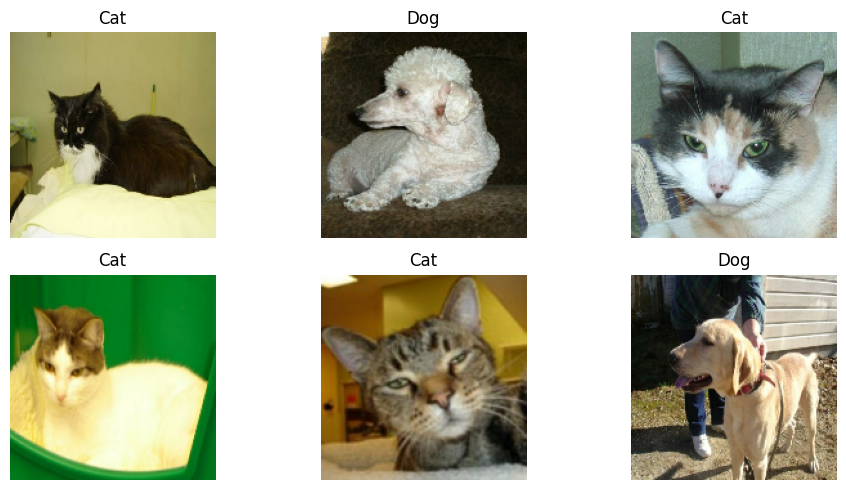

In [9]:

plt.figure(figsize=(10, 5))

for images, labels in train_data.take(1):
    for i in range(6):
        plt.subplot(2, 3, i + 1)
        plt.imshow(images[i].numpy())

        label = "Dog" if labels[i].numpy() == 1 else "Cat"
        plt.title(label)
        plt.axis("off")

plt.tight_layout()
plt.show()


In [10]:

from tensorflow import keras
from tensorflow.keras import layers

model = keras.Sequential([
    keras.Input(shape=(160, 160, 3)),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D(),

    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()



Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 158, 158, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 79, 79, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 77, 77, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 38, 38, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 36, 36, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 18, 18, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 41472)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     5,308,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,401,921 (20.61 MB)

 Trainable params: 5,401,921 (20.61 MB)

 Non-trainable params: 0 (0.00 B)

In [11]:

EPOCHS = 5

history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=EPOCHS
)


Epoch 1/5
582/582 ━━━━━━━━━━━━━━━━━━━━ 45s 60ms/step - accuracy: 0.6736 - loss: 0.5980 - val_accuracy: 0.7481 - val_loss: 0.5007
Epoch 2/5
582/582 ━━━━━━━━━━━━━━━━━━━━ 68s 47ms/step - accuracy: 0.7652 - loss: 0.4876 - val_accuracy: 0.7870 - val_loss: 0.4575
Epoch 3/5
582/582 ━━━━━━━━━━━━━━━━━━━━ 28s 47ms/step - accuracy: 0.8068 - loss: 0.4204 - val_accuracy: 0.8089 - val_loss: 0.4153
Epoch 4/5
582/582 ━━━━━━━━━━━━━━━━━━━━ 28s 47ms/step - accuracy: 0.8430 - loss: 0.3587 - val_accuracy: 0.8248 - val_loss: 0.4008
Epoch 5/5
582/582 ━━━━━━━━━━━━━━━━━━━━ 28s 47ms/step - accuracy: 0.8689 - loss: 0.3037 - val_accuracy: 0.8233 - val_loss: 0.4190


In [12]:
model.save("cat_dog_model.keras")

model.save_weights("cat_dog_weights.weights.h5")

print("Model and weights saved successfully!")

Model and weights saved successfully!


In [13]:
from google.colab import files

files.download("cat_dog_model.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [14]:
from google.colab import files

files.download("cat_dog_weights.weights.h5")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>